<a href="https://colab.research.google.com/github/lgonperez3-glitch/MLSM-labs/blob/main/Lab2/lab2_task2_colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lab 2 — Task 2: Clasificación de géneros musicales con VGG16

Notebook independiente para la **Task 2**. Utiliza *transfer learning* con VGG16 preentrenada en ImageNet para clasificar imágenes de espectrogramas según su género musical.

**Flujo de trabajo:** configurar el entorno → cargar y comprobar imágenes → separar train/validation/test → preparar los datos → cargar el extractor VGG16 → añadir una cabeza de clasificación → entrenar y seleccionar la mejor época con validación → evaluar una sola vez sobre test.

**Separación de datos:** se reserva el 20 % para test desde el principio. Del 80 % restante, se reserva el 20 % para validación. Por tanto, aproximadamente el 64 % se utiliza para entrenar, el 16 % para validar y el 20 % para la evaluación final.

**Principio importante:** no se utiliza el conjunto de test para decidir la arquitectura, ajustar hiperparámetros ni elegir la época. Esto evita adaptar las decisiones al resultado de la evaluación final.

**Antes de ejecutar:** comprueba que `DATA_DIR` apunta a `images_original` y que cada género está en una subcarpeta. Ejecuta las celdas en orden.

## Preparar Google Colab

Este notebook está preparado para ejecutarse en Google Colab. Antes de empezar, puedes seleccionar **Entorno de ejecución → Cambiar tipo de entorno de ejecución → T4 GPU** para acelerar el entrenamiento (si está disponible).

Los datos deben estar en Google Drive, dentro de una carpeta `images_original` que contenga una subcarpeta por género. La siguiente celda monta Drive; después configura `DATA_DIR` con la ruta real de tu carpeta.

In [3]:
# Montar Google Drive para acceder al dataset desde Colab.
from google.colab import drive
drive.mount('/content/drive')

# Comprueba que la ruta coincide con la ubicación de images_original en tu Drive.
# Ejemplo: /content/drive/MyDrive/GTZAN/images_original

Mounted at /content/drive


In [4]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 1. Imports y configuración

TensorFlow/Keras implementa VGG16. Si faltan librerías, descomenta y ejecuta la instalación.

### Qué hace este bloque y por qué

- **Instalación:** la línea `%pip install` está comentada para evitar reinstalar paquetes en cada ejecución. Actívala solo si el entorno no tiene las dependencias.
- **Imports:** `os` permite recorrer carpetas; `random` y `numpy` gestionan aleatoriedad y arrays; `matplotlib` dibuja gráficos; `tensorflow` proporciona Keras y el pipeline de imágenes.
- **`train_test_split`** divide los datos sin tener que implementar la partición manualmente. Las métricas de `sklearn` sirven para evaluar el resultado más allá de una única accuracy.
- **`SEED = 42`:** fija las fuentes principales de aleatoriedad para facilitar comparaciones reproducibles. No garantiza determinismo absoluto en todos los dispositivos y operaciones GPU.
- **Importante:** ejecutar de nuevo una celda puede redefinir variables y volver a inicializar el modelo; ejecuta el notebook en orden.

In [5]:
# %pip install tensorflow scikit-learn matplotlib
import os
import random
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

# Fijar las semillas hace más reproducible la partición y la inicialización del modelo.
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)
print("TensorFlow:", tf.__version__)

TensorFlow: 2.21.0


## 2. Cargar imágenes y dividir los datos

Cambia `DATA_DIR` para que apunte a `images_original`. La división inicial reserva el 20 % para test. La validación se extrae únicamente del 80 % restante.

### Cómo se construye el conjunto de datos

- **`DATA_DIR`:** debe apuntar a una carpeta que contenga una subcarpeta por género musical. Ajusta la ruta a tu entorno local o a Google Colab.
- **`IMG_SIZE = (224, 224)`:** VGG16 espera imágenes de 224 × 224 píxeles con tres canales RGB.
- **`BATCH_SIZE = 32`:** el modelo procesa hasta 32 imágenes por paso de entrenamiento. Un lote mayor puede acelerar el entrenamiento, pero consume más memoria; si aparece un error de memoria, prueba 16 o 8.
- **`class_names`:** ordena alfabéticamente las subcarpetas y asigna a cada género un índice entero. Este orden se reutiliza al mostrar resultados, por lo que no debe cambiar entre entrenamiento y evaluación.
- **`paths` y `labels`:** guardan, respectivamente, la ruta de cada imagen y su clase numérica. Solo se admiten extensiones de imagen indicadas en `extensions`.
- **Comprobaciones:** se detiene la ejecución si la ruta no existe o no contiene imágenes reconocibles, en vez de continuar con datos vacíos.
- **Partición de datos:** primero se reserva el 20 % para test. Del 80 % restante se reserva el 20 % para validación. En total queda aproximadamente **64 % train, 16 % validation y 20 % test**.
- **`stratify`:** mantiene aproximadamente la proporción de géneros en cada partición. `random_state=SEED` permite reproducir la separación. El conjunto de test no debe utilizarse para ajustar hiperparámetros ni escoger la época.

In [6]:
# Ruta de la carpeta con una subcarpeta por género musical.
DATA_DIR = '/content/drive/MyDrive/MLSM/Data/images_original'  # Cambia esta ruta según la ubicación real en Drive.
IMG_SIZE = (224, 224)               # Tamaño requerido por VGG16.
BATCH_SIZE = 32

if not os.path.isdir(DATA_DIR):
    raise FileNotFoundError(f"No encuentro {DATA_DIR}. Cambia DATA_DIR a images_original.")

# Cada subcarpeta representa un género musical.
class_names = sorted([d for d in os.listdir(DATA_DIR)
                      if os.path.isdir(os.path.join(DATA_DIR, d))])
extensions = ('.png', '.jpg', '.jpeg', '.bmp')
paths, labels = [], []
for label, genre in enumerate(class_names):
    folder = os.path.join(DATA_DIR, genre)
    for filename in sorted(os.listdir(folder)):
        if filename.lower().endswith(extensions):
            paths.append(os.path.join(folder, filename))
            labels.append(label)

paths, labels = np.array(paths), np.array(labels)
if len(paths) == 0:
    raise ValueError("No se han encontrado imágenes. Comprueba la estructura de carpetas.")

print("Géneros:", class_names)
print("Total de imágenes:", len(paths))

# División solicitada: 80 % para desarrollo y 20 % reservado para evaluación final.
# stratify mantiene la proporción de cada género en ambos conjuntos.
dev_paths, test_paths, dev_labels, test_labels = train_test_split(
    paths, labels, test_size=0.20, random_state=SEED, stratify=labels
)

# La validación se extrae del 80 % de desarrollo, nunca del conjunto de test.
train_paths, val_paths, train_labels, val_labels = train_test_split(
    dev_paths, dev_labels, test_size=0.20, random_state=SEED, stratify=dev_labels
)
print(f"Train: {len(train_paths)} | Validation: {len(val_paths)} | Test: {len(test_paths)}")
print(f"Porcentajes: train={len(train_paths)/len(paths):.1%}, "
      f"validation={len(val_paths)/len(paths):.1%}, test={len(test_paths)/len(paths):.1%}")

Géneros: ['blues', 'classical', 'country', 'disco', 'hiphop', 'jazz', 'metal', 'pop', 'reggae', 'rock']
Total de imágenes: 999
Train: 639 | Validation: 160 | Test: 200
Porcentajes: train=64.0%, validation=16.0%, test=20.0%


## 3. Preparar los datasets

Las imágenes se decodifican como RGB y se redimensionan a 224 × 224. Se mezclan solo los datos de entrenamiento; validación y test conservan su orden para poder comparar las predicciones con las etiquetas originales.

### Preparación y carga de imágenes, paso a paso

- **`load_image`:** lee cada archivo, lo decodifica en RGB y lo redimensiona al tamaño requerido por VGG16. La etiqueta se devuelve sin modificar.
- **`set_shape`:** declara que la imagen tiene tres canales, aunque la altura y anchura originales sean variables; esto ayuda a TensorFlow a determinar la forma de los tensores.
- **`make_dataset`:** convierte las rutas y etiquetas en un `tf.data.Dataset`, que permite procesar imágenes sin cargar todas las imágenes de golpe en memoria.
- **`shuffle(len(file_paths), seed=SEED)`:** mezcla únicamente el conjunto de entrenamiento. La mezcla reduce la dependencia del orden de los archivos; validación y test permanecen ordenados.
- **`map(..., num_parallel_calls=AUTOTUNE)`:** permite decodificar varias imágenes en paralelo.
- **`batch(BATCH_SIZE)`:** agrupa ejemplos para cada paso de entrenamiento/evaluación. **`prefetch(AUTOTUNE)`** prepara lotes mientras el modelo procesa el anterior.
- **Visualización:** muestra ejemplos y sus etiquetas para detectar rutas o etiquetas incorrectas antes de entrenar. Si los espectrogramas parecen deformados, recuerda que el redimensionado cambia su tamaño espacial.

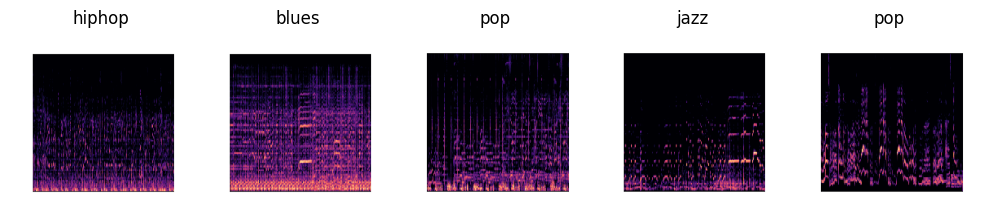

In [7]:
def load_image(path, label):
    # Lee el archivo y decodifica la imagen con tres canales de color.
    image = tf.io.read_file(path)
    image = tf.image.decode_image(image, channels=3, expand_animations=False)
    image.set_shape([None, None, 3])
    # VGG16 requiere entradas de 224 x 224 píxeles.
    image = tf.image.resize(image, IMG_SIZE)
    return image, label

def make_dataset(file_paths, file_labels, training=False):
    ds = tf.data.Dataset.from_tensor_slices((file_paths, file_labels))
    if training:
        # Mezclar el orden de entrenamiento ayuda a evitar que el orden de archivos influya.
        ds = ds.shuffle(len(file_paths), seed=SEED)
    ds = ds.map(load_image, num_parallel_calls=tf.data.AUTOTUNE)
    # Los lotes y prefetch hacen más eficiente la carga de datos.
    return ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

train_ds = make_dataset(train_paths, train_labels, training=True)
val_ds = make_dataset(val_paths, val_labels)
test_ds = make_dataset(test_paths, test_labels)

# Mostrar algunos ejemplos sirve para comprobar que las etiquetas y las imágenes son correctas.
for images, labels_batch in train_ds.take(1):
    plt.figure(figsize=(10, 3))
    for i in range(min(5, len(images))):
        plt.subplot(1, 5, i + 1)
        plt.imshow(tf.cast(images[i], tf.uint8))
        plt.title(class_names[int(labels_batch[i])])
        plt.axis('off')
    plt.tight_layout()
    plt.show()

## 4. Cargar VGG16 preentrenada

Se eliminan las capas finales de ImageNet porque clasifican 1000 categorías distintas. Congelamos las capas convolucionales para reutilizar sus características visuales sin reentrenar todo el modelo, lo que reduce el coste computacional.

### Qué significa reutilizar VGG16

- **VGG16** es una red convolucional entrenada previamente con ImageNet, un conjunto de imágenes generales. Aquí se reutiliza como extractor de características visuales de los espectrogramas.
- **`weights='imagenet'`:** carga pesos aprendidos previamente, en lugar de empezar con pesos aleatorios. La primera ejecución puede necesitar descargar esos pesos.
- **`include_top=False`:** elimina el clasificador original de 1000 categorías de ImageNet; añadiremos uno nuevo con las categorías musicales presentes en este dataset.
- **`input_shape=(224, 224, 3)`:** fija el tamaño y número de canales de entrada.
- **`base.trainable = False`:** congela los pesos convolucionales. Así, durante el entrenamiento solo se actualizan las capas nuevas, lo que reduce el tiempo y el riesgo de destruir las características preentrenadas.
- **Consecuencia:** esto es *transfer learning* con extractor congelado, no un ajuste fino (*fine-tuning*) de todas las capas.

In [8]:
# include_top=False elimina la cabeza de clasificación original de ImageNet.
base = tf.keras.applications.VGG16(
    weights='imagenet', include_top=False, input_shape=(224, 224, 3)
)

# Congelar VGG16 mantiene fijos los pesos preentrenados durante esta tarea.
base.trainable = False
base.summary()

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "vgg16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 224, 224, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 224, 224, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 112, 112, 128)  │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 112, 112, 128)  │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 56, 56, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 28, 28, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 28, 28, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 14, 14, 512)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool (MaxPooling2D)      │ (None, 7, 7, 512)      │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,714,688 (56.13 MB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 14,714,688 (56.13 MB)

## 5. Añadir una cabeza para los géneros musicales

VGG16 necesita su función de preprocesamiento específica. GlobalAveragePooling2D resume los mapas de características con menos parámetros que Flatten. La regularización L2 y Dropout ayudan a reducir el sobreajuste de la cabeza de clasificación.

### Diseño de la cabeza de clasificación y factores que afectan al aprendizaje

1. **Entrada:** recibe imágenes RGB redimensionadas. Los valores todavía están en el rango habitual de píxeles (aproximadamente 0–255).
2. **Aumento de datos:** `RandomTranslation(0.05, 0.05)`, `RandomZoom(0.1)` y `RandomContrast(0.1)` aplican pequeñas transformaciones aleatorias durante el entrenamiento. Buscan reducir el sobreajuste, no crean nuevas etiquetas. Si estas transformaciones alteran información musical relevante de los espectrogramas, conviene reducirlas o eliminarlas y comparar en validación.
3. **`preprocess_input`:** transforma los canales al formato que espera VGG16 preentrenada. No se debe sustituir por una normalización arbitraria sin adaptar el preprocesamiento.
4. **Extractor congelado:** `base(x, training=False)` calcula características con VGG16 sin actualizar sus pesos.
5. **`GlobalAveragePooling2D`:** promedia espacialmente cada mapa de características. Frente a `Flatten`, suele generar una representación mucho más pequeña y menos parámetros entrenables.
6. **Capa densa de 256 unidades y ReLU:** aprende combinaciones de características para distinguir los géneros. El número 256 es un hiperparámetro: más unidades aumentan capacidad y coste y pueden favorecer sobreajuste; menos unidades reducen ambos.
7. **Regularización L2 (`1e-4`):** penaliza pesos grandes en esa capa. El valor controla la intensidad de la penalización; valores excesivos pueden limitar el aprendizaje.
8. **Dropout (`0.4`):** desactiva aleatoriamente el 40 % de las activaciones de esa capa durante el entrenamiento. Solo actúa al entrenar, no al evaluar.
9. **Salida softmax:** crea una probabilidad por género. `len(class_names)` adapta el número de salidas a las carpetas encontradas.

La arquitectura y los valores anteriores son decisiones de diseño, no valores universalmente óptimos. Para compararlos, modifica un factor cada vez y usa la validación, nunca el test.

In [9]:
# La entrada se mantiene en el rango 0–255 hasta aplicar preprocess_input.
inputs = tf.keras.Input(shape=(224, 224, 3))

# Aumento de datos ligero: pequeñas transformaciones para reducir el sobreajuste.
# Estas capas aplican transformaciones aleatorias durante el entrenamiento.
x = tf.keras.layers.RandomTranslation(0.05, 0.05)(inputs)
x = tf.keras.layers.RandomZoom(0.1)(x)
x = tf.keras.layers.RandomContrast(0.1)(x)

# Convierte los píxeles al formato esperado por los pesos preentrenados de VGG16.
x = tf.keras.applications.vgg16.preprocess_input(x)

# Extrae características visuales con VGG16 congelada.
x = base(x, training=False)

# Resume cada mapa espacial y reduce la cantidad de parámetros entrenables.
x = tf.keras.layers.GlobalAveragePooling2D()(x)

# La cabeza aprende qué características distinguen los géneros musicales.
x = tf.keras.layers.Dense(
    256, activation='relu',
    kernel_regularizer=tf.keras.regularizers.l2(1e-4)  # Penaliza pesos grandes.
)(x)

# Dropout desactiva parte de las activaciones durante el entrenamiento para regularizar.
x = tf.keras.layers.Dropout(0.4)(x)

# Softmax produce una probabilidad por cada género.
outputs = tf.keras.layers.Dense(len(class_names), activation='softmax')(x)
vgg_model = tf.keras.Model(inputs, outputs)
vgg_model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ random_translation  │ (None, 224, 224,  │          0 │ input_layer_1[0]… │
│ (RandomTranslation) │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ random_zoom         │ (None, 224, 224,  │          0 │ random_translati… │
│ (RandomZoom)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ random_contrast     │ (None, 224, 224,  │          0 │ random_zoom[0][0] │
│ (RandomContrast)    │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item (GetItem)  │ (None, 224, 224)  │          0 │ random_contrast[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_1          │ (None, 224, 224)  │          0 │ random_contrast[… │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_2          │ (None, 224, 224)  │          0 │ random_contrast[… │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stack (Stack)       │ (None, 224, 224,  │          0 │ get_item[0][0],   │
│                     │ 3)                │            │ get_item_1[0][0], │
│                     │                   │            │ get_item_2[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 224, 224,  │          0 │ stack[0][0]       │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ vgg16 (Functional)  │ (None, 7, 7, 512) │ 14,714,688 │ add[0][0]         │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 512)       │          0 │ vgg16[0][0]       │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 256)       │    131,328 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 256)       │          0 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 10)        │      2,570 │ dropout[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 14,848,586 (56.64 MB)

 Trainable params: 133,898 (523.04 KB)

 Non-trainable params: 14,714,688 (56.13 MB)

## 6. Entrenar el modelo

Adam usa un learning rate pequeño para entrenar la cabeza sin alterar el extractor preentrenado. EarlyStopping vigila la accuracy de validación y restaura los pesos de la mejor época. Se pueden ejecutar hasta 15 épocas, pero el entrenamiento puede detenerse antes.

### Qué se optimiza durante el entrenamiento

- **`Adam(learning_rate=1e-4)`:** Adam adapta las actualizaciones de los pesos; el *learning rate* controla el tamaño de los pasos. `0.0001` es relativamente pequeño y suele ser razonable para una cabeza nueva sobre un extractor preentrenado. Si es demasiado alto, el aprendizaje puede ser inestable; si es demasiado bajo, puede avanzar lentamente.
- **`sparse_categorical_crossentropy`:** función de pérdida apropiada cuando cada etiqueta es un entero que representa una clase. No hace falta convertir las etiquetas a vectores *one-hot*.
- **`accuracy`:** proporción de predicciones cuya clase más probable coincide con la etiqueta correcta. No sustituye a las métricas por clase.
- **`EarlyStopping`:** vigila `val_accuracy`. `mode='max'` significa que más alto es mejor; `patience=3` permite tres épocas sin mejora antes de parar; `restore_best_weights=True` recupera los pesos de la época con mejor accuracy de validación.
- **`epochs=15`:** número máximo de pasadas completas por los datos de entrenamiento; EarlyStopping puede terminar antes.
- **`shuffle=False` en `fit`:** el propio `train_ds` ya mezcla los ejemplos con `Dataset.shuffle()`, por eso no hace falta mezclarlos otra vez aquí.
- **Selección del modelo:** la mejor época se elige mediante validación. El valor impreso es la mayor `val_accuracy` registrada; los pesos finales restaurados corresponden a esa mejor época según el criterio de EarlyStopping.

In [12]:
vgg_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss='sparse_categorical_crossentropy',  # Las etiquetas son números enteros.
    metrics=['accuracy']
)

# Detener si val_accuracy no mejora durante 3 épocas y recuperar los mejores pesos.
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor='val_accuracy', mode='max', patience=3, restore_best_weights=True
)

vgg_history = vgg_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    shuffle=False,  # train_ds ya se mezcla mediante Dataset.shuffle().
    callbacks=[early_stop]
)

best_val_accuracy = max(vgg_history.history['val_accuracy'])
print(f"Mejor validation accuracy: {best_val_accuracy:.4f}")

Epoch 1/15
20/20 ━━━━━━━━━━━━━━━━━━━━ 86s 4s/step - accuracy: 0.1424 - loss: 5.0728 - val_accuracy: 0.2562 - val_loss: 2.8316
Epoch 2/15
20/20 ━━━━━━━━━━━━━━━━━━━━ 4s 200ms/step - accuracy: 0.1643 - loss: 4.4340 - val_accuracy: 0.3313 - val_loss: 2.3407
Epoch 3/15
20/20 ━━━━━━━━━━━━━━━━━━━━ 5s 249ms/step - accuracy: 0.1690 - loss: 3.8971 - val_accuracy: 0.3688 - val_loss: 2.1598
Epoch 4/15
20/20 ━━━━━━━━━━━━━━━━━━━━ 5s 232ms/step - accuracy: 0.1862 - loss: 3.6195 - val_accuracy: 0.3688 - val_loss: 2.0380
Epoch 5/15
20/20 ━━━━━━━━━━━━━━━━━━━━ 4s 215ms/step - accuracy: 0.2238 - loss: 3.2862 - val_accuracy: 0.3938 - val_loss: 1.9970
Epoch 6/15
20/20 ━━━━━━━━━━━━━━━━━━━━ 4s 201ms/step - accuracy: 0.2754 - loss: 3.0063 - val_accuracy: 0.3500 - val_loss: 1.8764
Epoch 7/15
20/20 ━━━━━━━━━━━━━━━━━━━━ 4s 202ms/step - accuracy: 0.2692 - loss: 2.7455 - val_accuracy: 0.3875 - val_loss: 1.8406
Epoch 8/15
20/20 ━━━━━━━━━━━━━━━━━━━━ 4s 197ms/step - accuracy: 0.2942 - loss: 2.6208 - val_accuracy: 0.37

## 7. Curvas de entrenamiento

La accuracy muestra qué proporción de ejemplos se clasifica correctamente. La loss refleja el error de las probabilidades del modelo. Comparar entrenamiento y validación ayuda a detectar sobreajuste.

### Cómo interpretar las curvas

- **Accuracy de train frente a validation:** si train sigue mejorando y validation se estanca o empeora, puede haber sobreajuste.
- **Loss de train frente a validation:** si la pérdida de validación empieza a subir mientras la de entrenamiento baja, es otra señal de sobreajuste. La loss y la accuracy miden aspectos distintos, así que pueden evolucionar de manera diferente.
- **Eje horizontal:** número de época; cada época recorre una vez los datos de entrenamiento.
- **No compares solo el último punto:** EarlyStopping restaura los mejores pesos según `val_accuracy`, por lo que interesa identificar la época seleccionada.
- **Nota:** las curvas describen el entrenamiento y la validación. No muestran resultados del test ni deben usarse para ajustar decisiones después de observar el test.

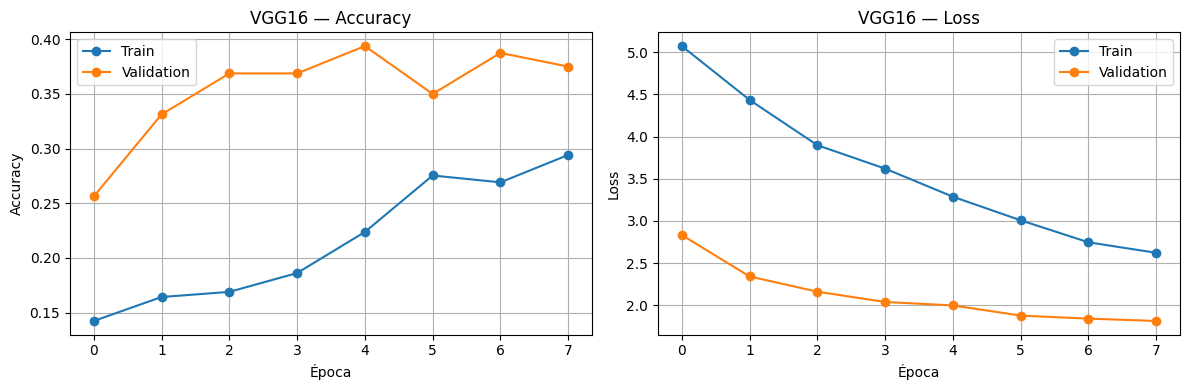

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(vgg_history.history['accuracy'], marker='o', label='Train')
axes[0].plot(vgg_history.history['val_accuracy'], marker='o', label='Validation')
axes[0].set(title='VGG16 — Accuracy', xlabel='Época', ylabel='Accuracy')
axes[0].legend()
axes[0].grid(True)

axes[1].plot(vgg_history.history['loss'], marker='o', label='Train')
axes[1].plot(vgg_history.history['val_loss'], marker='o', label='Validation')
axes[1].set(title='VGG16 — Loss', xlabel='Época', ylabel='Loss')
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

## 8. Evaluación final sobre test

Una vez seleccionados los pesos con validación, evaluamos el modelo sobre el 20 % reservado. Este conjunto no se utiliza para entrenar ni seleccionar la mejor época, siguiendo el enunciado.

### Evaluación: qué mide cada salida

- **`evaluate(test_ds)`:** calcula la pérdida y accuracy sobre datos reservados que no han intervenido en el entrenamiento ni en la selección de época. Esta es la estimación final de generalización para esta partición.
- **`predict(test_ds)`:** devuelve un vector de probabilidades por imagen. `argmax(axis=1)` convierte cada vector en la clase con mayor probabilidad.
- **`y_true = test_labels`:** contiene las etiquetas reales en el mismo orden que `test_ds`, porque el dataset de test no se mezcla.
- **Informe de clasificación:** `precision` mide qué proporción de las predicciones de una clase acierta; `recall` mide qué proporción de los ejemplos reales de esa clase detecta; `f1` combina ambas; `support` indica cuántos ejemplos reales hay por clase.
- **`zero_division=0`:** evita una advertencia y asigna cero cuando una métrica no puede calcularse porque no hay predicciones para una clase.
- **Matriz de confusión:** filas = clase real y columnas = clase predicha. Los valores de la diagonal son aciertos; fuera de ella aparecen las confusiones entre géneros.
- **Precaución:** si se prueban muchas configuraciones y se escoge una mirando repetidamente el resultado de test, deja de ser una evaluación independiente. Para comparar modelos, utiliza validación y reserva test para el resultado final.

VGG16 — test loss: 1.9211
VGG16 — test accuracy: 0.3750

Informe de clasificación en test:
              precision    recall  f1-score   support

       blues       0.00      0.00      0.00        20
   classical       0.48      0.80      0.60        20
     country       0.38      0.25      0.30        20
       disco       0.29      0.10      0.15        20
      hiphop       0.47      0.70      0.56        20
        jazz       0.29      0.20      0.24        20
       metal       0.50      0.40      0.44        20
         pop       0.27      0.70      0.39        20
      reggae       0.56      0.50      0.53        20
        rock       0.15      0.10      0.12        20

    accuracy                           0.38       200
   macro avg       0.34      0.38      0.33       200
weighted avg       0.34      0.38      0.33       200



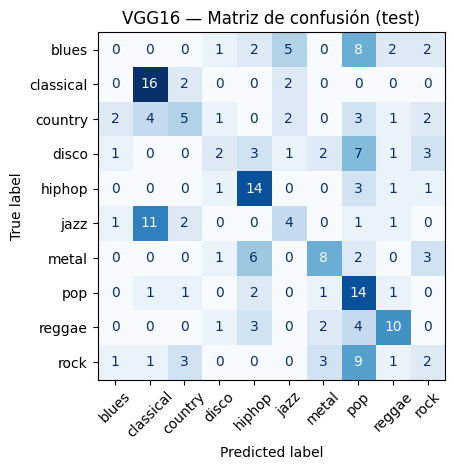

In [16]:
# Evaluación final sobre el conjunto de test reservado.
test_loss, test_accuracy = vgg_model.evaluate(test_ds, verbose=0)
print(f"VGG16 — test loss: {test_loss:.4f}")
print(f"VGG16 — test accuracy: {test_accuracy:.4f}")

# Obtener las clases predichas para calcular métricas por género.
# test_ds no se mezcla, por lo que el orden coincide con test_labels.
y_true = test_labels
y_prob = vgg_model.predict(test_ds, verbose=0)
y_pred = np.argmax(y_prob, axis=1)

print("\nInforme de clasificación en test:")
print(classification_report(
    y_true, y_pred, labels=range(len(class_names)),
    target_names=class_names, zero_division=0
))

# La matriz de confusión muestra qué géneros se confunden entre sí.
cm = confusion_matrix(y_true, y_pred, labels=range(len(class_names)))
ConfusionMatrixDisplay(cm, display_labels=class_names).plot(
    xticks_rotation=45, cmap='Blues', colorbar=False
)
plt.title('VGG16 — Matriz de confusión (test)')
plt.tight_layout()
plt.show()

## 9. Conclusión y notas

Al terminar, registra la mejor *validation accuracy*, la *test accuracy* y las métricas por género. Compara Task 2 con Task 1 solo si ambas evaluaciones utilizan una partición comparable; si las particiones difieren, la comparación puede no ser justa.

- La primera ejecución puede descargar los pesos de VGG16 preentrenada en ImageNet.
- Si no hay GPU disponible, el notebook puede ejecutarse en CPU, aunque VGG16 puede tardar bastante.
- Si aparece un error de memoria, reduce `BATCH_SIZE` (por ejemplo, de 32 a 16 o 8) y vuelve a ejecutar las celdas que crean los datasets y el modelo si es necesario.
- La accuracy depende de la calidad y cantidad de datos, la partición, el preprocesamiento, la arquitectura y los hiperparámetros; no se puede garantizar una mejora sin ejecutar y comparar experimentos.
- Si hay varias imágenes de una misma canción, conviene dividir por canción original en vez de por imagen. De lo contrario, imágenes muy relacionadas podrían aparecer en train y test y producir una estimación demasiado optimista.
- VGG16 fue preentrenada con imágenes naturales, no específicamente con espectrogramas. El uso de transferencia de aprendizaje es una decisión práctica que debe evaluarse empíricamente.

### Checklist para interpretar los resultados

1. ¿Las curvas de train y validation sugieren sobreajuste?
2. ¿Qué géneros tienen menor precision, recall o F1?
3. ¿Qué pares de géneros aparecen más confundidos en la matriz de confusión?
4. ¿La comparación con Task 1 utiliza los mismos datos de test y el mismo criterio de evaluación?